---
## 4. Results
*Lead: Brian Ooi*

Monte Carlo gives a distribution for the project completion date, rather than a single duration and a normal approximation. It shows how likely the plan is to be met and which tasks control that risk. Sections 4.1 to 4.4 compare PERT with simulation, connect criticality to sensitivity, apply the result to PSPLIB J30 networks, and test what makes a network fragile.

In [1]:
# Setup: imports, plotting style and random seed
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "mcpert").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # makes the mcpert package importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

import mcpert as mc
from mcpert.examples import dinner, software_release
from mcpert.style import BLUE, ORANGE, AQUA, INK, MUTED, use_style

use_style()
SEED = 2026  # every number in this notebook is reproducible

In [2]:
# Data used in this part
project, pert_model = software_release()          # the 7-task running example (Part 3)
ratios = mc.load_sip()["ratio"].to_numpy()        # SiP ratios actual / estimate (Part 1)

### 4.1 PERT versus Monte Carlo on the running example

In [3]:
# What PERT promises, and what really happens
# 1. Simulate the delivery date and calculate the classical PERT quantities.
T = mc.simulate(project, pert_model, n=200_000, rng=SEED)
plan = project.planned_duration()
pert_date = mc.pert_duration(project, pert_model)
pert_mu, pert_sd = mc.pert_normal_approx(project, pert_model)
pert_90 = pert_mu + stats.norm.ppf(0.9) * pert_sd

# 2. Monte Carlo estimates include 95% confidence intervals.
mc_mean = mc.mean_ci(T)
mc_90 = mc.quantile_ci(T, 0.9)
mc_pert_prob = mc.prob_ci(T <= pert_date)
mc_plan_prob = mc.prob_ci(T <= plan)

# 3. Put PERT and Monte Carlo estimates in one table.
comparison = pd.DataFrame({
    "PERT": [pert_date, pert_90, stats.norm.cdf(pert_date, pert_mu, pert_sd), stats.norm.cdf(plan, pert_mu, pert_sd)],
    "Monte Carlo": [mc_mean.value, mc_90.value, mc_pert_prob.value, mc_plan_prob.value],
    "95% interval": [mc_mean.interval, mc_90.interval, mc_pert_prob.interval, mc_plan_prob.interval],
}, index=["Expected duration", "90% date", "P(on time at PERT date)", "P(on time at naive plan)"])
table = comparison.copy()
table[["PERT", "Monte Carlo"]] = table[["PERT", "Monte Carlo"]].round(4)
display(table)

,PERT,Monte Carlo,95% interval
Expected duration,23.5000,24.2684,"[24.26, 24.28]"
90% date,27.3438,28.0139,"[27.99, 28.04]"
P(on time at PERT date),0.5000,0.4120,"[0.409, 0.4151]"
P(on time at naive plan),0.2023,0.1240,"[0.121, 0.1271]"


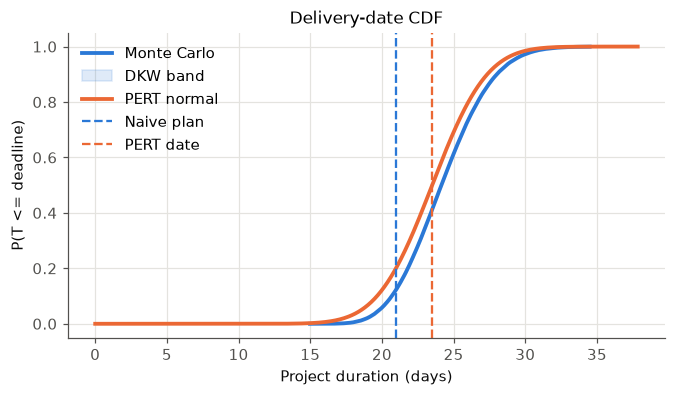

In [4]:
# Distribution of the delivery date, with a 95% band valid for all dates at once (DKW)
# 1. Plot the empirical CDF and the simultaneous DKW band.
T_sorted = np.sort(T)
keep = np.r_[0:T_sorted.size:50]
cdf = np.arange(1, T_sorted.size + 1) / T_sorted.size
radius = mc.dkw_radius(T_sorted.size)
plt.plot(T_sorted[keep], cdf[keep], color=BLUE, linewidth=2.5, label="Monte Carlo")
plt.fill_between(T_sorted[keep], np.clip(cdf[keep] - radius, 0, 1),
                 np.clip(cdf[keep] + radius, 0, 1), color=BLUE, alpha=0.15, label="DKW band")

# 2. Compare with PERT and mark both planning dates.
x = np.linspace(0, T_sorted.max(), 500)
plt.plot(x, stats.norm.cdf(x, pert_mu, pert_sd), color=ORANGE, linewidth=2.5, label="PERT normal")
plt.axvline(plan, color=BLUE, linestyle="--", linewidth=1.5, label="Naive plan")
plt.axvline(pert_date, color=ORANGE, linestyle="--", linewidth=1.5, label="PERT date")
plt.xlabel("Project duration (days)")
plt.ylabel("P(T <= deadline)")
plt.title("Delivery-date CDF")
plt.legend()
plt.show()

**Monte Carlo gives a later 90% date and a lower probability of meeting the PERT date than the classical normal approximation.** The gap is not just Monte Carlo sampling noise, because it is much larger than the DKW band at the relevant deadlines. PERT treats one mean critical path as certain and therefore underestimates tail risk. The Monte Carlo CDF is the more appropriate distribution because the empirical density of T comes from all simulated longest paths.


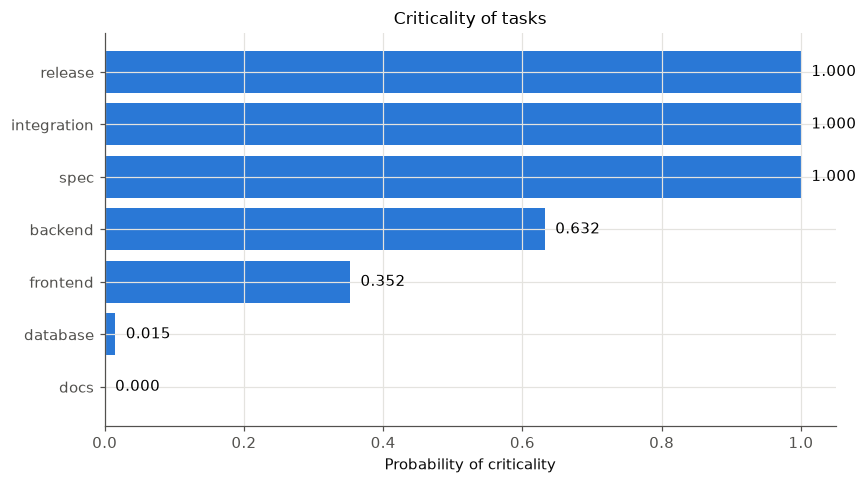

In [5]:
# Criticality index of each task
# 1. Estimate each task probability of lying on the longest path.
crit = mc.criticality_index(project, pert_model, n=100_000, rng=SEED)
order = np.argsort(crit)

# 2. Draw one sorted horizontal bar chart.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(np.arange(project.k), crit[order], color=BLUE)
ax.set_yticks(np.arange(project.k), [project.names[i] for i in order])
ax.set_xlabel("Probability of criticality")
ax.set_xlim(0, 1.05)
ax.set_title("Criticality of tasks")
for y, i in enumerate(order):
    ax.text(crit[i] + 0.015, y, f"{crit[i]:.3f}", va="center")
plt.tight_layout()
plt.show()

In [6]:
# Check the theorem: finite differences with common random numbers
# 1. Estimate the expected-duration derivative for every task.
rows = []
for i, name in enumerate(project.names):
    crit = mc.criticality_index(project, pert_model, n=100_000, rng=SEED)[i]
    slope = mc.shift_sensitivity(project, pert_model, task=i, h=0.01, n=100_000, rng=SEED)
    rows.append([name, crit, slope.value, slope.interval])

# 2. Display criticality beside the finite-difference slope.
criticality_table = pd.DataFrame(rows, columns=["Task", "Criticality index", "Finite-difference slope", "95% interval"])
criticality_table["Criticality index"] = criticality_table["Criticality index"].round(4)
criticality_table["Finite-difference slope"] = criticality_table["Finite-difference slope"].round(4)
display(criticality_table)

,Task,Criticality index,Finite-difference slope,95% interval
0,spec,1.0000,1.0000,"[1, 1]"
1,backend,0.6322,0.6329,"[0.6299, 0.6359]"
2,frontend,0.3524,0.3530,"[0.35, 0.3559]"
3,database,0.0154,0.0154,"[0.01467, 0.01619]"
4,docs,0.0000,0.0000,"[0, 0]"
5,integration,1.0000,1.0000,"[1, 1]"
6,release,1.0000,1.0000,"[1, 1]"


The criticality chart identifies which tasks can change the delivery date. PERT misses the probability that a branch becomes critical, while the finite-difference slopes measure the same result in days gained per day saved. A day saved on frontend is worth roughly its criticality index in expected project days. A day saved on docs is worth nearly zero when docs is not on a competing critical path.


In [7]:
# One PSPLIB network in detail
# 1. Read the first J30 network and impose SiP delays on its planned durations.
files = mc.psplib_files("j30")
network, info = mc.read_psplib(files[0])
sip_model = mc.EmpiricalRatio(network.durations, ratios)

# 2. Simulate 100,000 scenarios and report the decision quantities.
D = sip_model.sample(100_000, rng=np.random.default_rng(SEED))
T_psp = network.completion_time(D)
plan_psp = network.planned_duration()
mean_psp = mc.mean_ci(T_psp)
q90_psp = mc.quantile_ci(T_psp, 0.9)
prob_psp = mc.prob_ci(T_psp <= plan_psp)
detail = pd.DataFrame({
    "Estimate": [plan_psp, mean_psp.value, q90_psp.value, prob_psp.value],
    "95% interval": ["planned", mean_psp.interval, q90_psp.interval, prob_psp.interval],
}, index=["Planned date", "E[T]", "90% date", "P(on time)"])
display(detail)

,Estimate,95% interval
Planned date,41.000000,planned
E[T],130.778637,"[129.5, 132.1]"
90% date,167.291886,"[165.3, 169.1]"
P(on time),0.010900,"[0.006605, 0.01519]"


In [8]:
# All 480 J30 networks
# 1. Sample each network with the SiP ratio bootstrap.
rows = []
for path in files:
    network, info = mc.read_psplib(path)
    model = mc.EmpiricalRatio(network.durations, ratios)
    D = model.sample(20_000, rng=np.random.default_rng(SEED))
    T = network.completion_time(D)
    plan = network.planned_duration()
    criticality = network.critical_tasks(D).mean(axis=0)
    real_tasks = network.durations > 0
    near_count = int(np.sum((criticality > 0.05) & real_tasks))
    rows.append({
        "network": info["name"],
        "plan (days)": plan,
        "E[T]/plan": mc.mean_ci(T).value / plan,
        "90% date / plan": mc.quantile_ci(T, 0.9).value / plan,
        "P(on time)": mc.prob_ci(T <= plan).value,
        "near-critical tasks": near_count,
    })

# 2. Store and summarize the 480-network results.
j30 = pd.DataFrame(rows)
display(j30.describe())

,plan (days),E[T]/plan,90% date / plan,P(on time),near-critical tasks
count,480.000000,480.000000,480.000000,480.000000,480.000000
mean,52.275000,2.845803,3.743401,0.021630,24.062500
std,8.877936,0.265896,0.333380,0.014052,2.410886
min,31.000000,2.076767,2.741236,0.001800,16.000000
25%,46.000000,2.656409,3.504270,0.011187,23.000000
50%,53.000000,2.814798,3.704126,0.018075,24.000000
75%,58.000000,3.025367,3.974760,0.028663,26.000000
max,98.000000,3.672072,4.814796,0.079900,30.000000


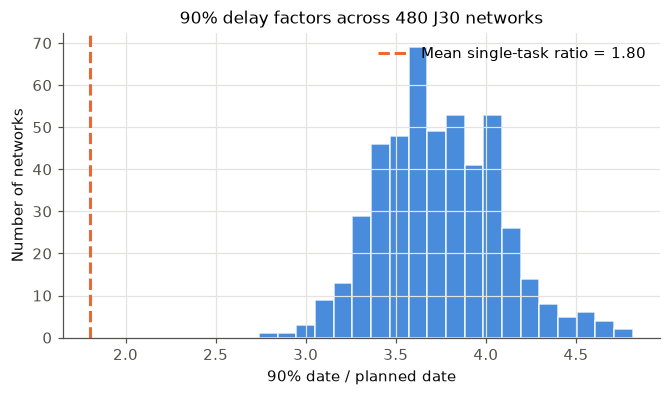

In [9]:
# How late are real-size projects?
# 1. Plot the distribution of delay factors.
plt.hist(j30["90% date / plan"], bins=20, color=BLUE, alpha=0.85, edgecolor="white")
plt.axvline(ratios.mean(), color=ORANGE, linestyle="--", linewidth=2,
            label=f"Mean single-task ratio = {ratios.mean():.2f}")
plt.xlabel("90% date / planned date")
plt.ylabel("Number of networks")
plt.title("90% delay factors across 480 J30 networks")
plt.legend()
plt.show()

**Real projects are much later than a single task average would suggest.** The network combines many uncertain durations and competing paths, so the 90% date is a larger factor than the mean SiP ratio of about 1.8. Delays accumulate on the longest path and a noncritical branch can become critical, creating additional tail delay.


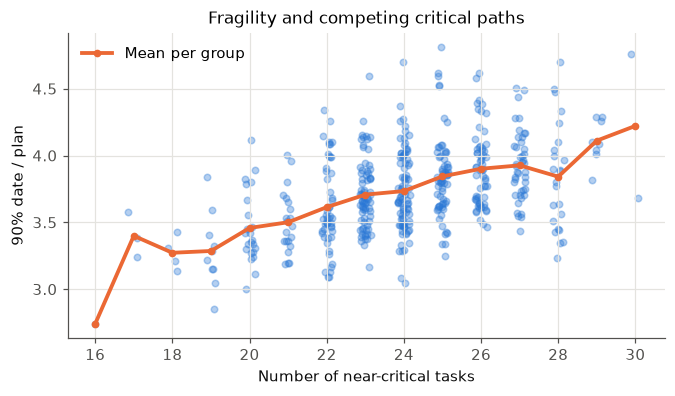

,90% date / plan,near-critical tasks,plan (days)
90% date / plan,1.000000,0.482341,-0.772922
near-critical tasks,0.482341,1.000000,-0.305612
plan (days),-0.772922,-0.305612,1.000000


In [10]:
# Delay factor versus the number of near-critical tasks
# 1. Scatter the networks and overlay the mean delay for each group.
jitter = np.random.default_rng(SEED).uniform(-0.15, 0.15, len(j30))
plt.scatter(j30["near-critical tasks"] + jitter, j30["90% date / plan"],
            color=BLUE, alpha=0.35, s=18)
means = j30.groupby("near-critical tasks")["90% date / plan"].mean()
plt.plot(means.index, means.values, color=ORANGE, linewidth=2.5,
         marker="o", markersize=4, label="Mean per group")
plt.xlabel("Number of near-critical tasks")
plt.ylabel("90% date / plan")
plt.title("Fragility and competing critical paths")
plt.legend()
plt.show()

# 2. Display the pairwise correlations.
correlation = j30[["90% date / plan", "near-critical tasks", "plan (days)"]].corr()
display(correlation)

**More near-critical tasks are associated with a later 90% date, while longer plans are comparatively less fragile as a ratio.** A network with many near-critical tasks has more ways for a branch to control completion, so the maximum moves upward as scenarios change. The negative correlation with plan length means long planned networks tend to have a lower delay factor despite remaining susceptible to absolute delay.
